In [1]:
#import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
energy = pd.read_csv("../data/raw/chicago_energy_raw.csv")
energy_filtered = energy[
    (energy["Data Year"] >= 2016) &
    (energy["Data Year"] <= 2023)
].copy()

In [9]:
energy_filtered.head()

,Data Year,ID,Property Name,Reporting Status,Address,ZIP Code,Chicago Energy Rating,Exempt From Chicago Energy Rating,Community Area,Primary Property Type,...,Site EUI (kBtu/sq ft),Source EUI (kBtu/sq ft),Weather Normalized Site EUI (kBtu/sq ft),Weather Normalized Source EUI (kBtu/sq ft),Total GHG Emissions (Metric Tons CO2e),GHG Intensity (kg CO2e/sq ft),Latitude,Longitude,Location,Row_ID
0,2021,101671,NaN,Not Submitted,6101 6115 N SEELEY AVE,60659,0.0,False,WEST RIDGE,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,41.990462,-87.706208,"(41.99046172, -87.70620782)",2021-101671
1,2021,101826,Drexel Building,Not Submitted,8136 8142 S DREXEL AVE,60619,0.0,False,CHATHAM,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,41.744013,-87.605499,"(41.74401302, -87.60549928)",2021-101826
2,2021,102323,NaN,Not Submitted,3515 3525 W FRANKLIN BLVD,60624,0.0,False,HUMBOLDT PARK,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,41.880824,-87.723279,"(41.8808242, -87.72327934)",2021-102323
3,2022,256888,NaN,Submitted Data,318 N CARPENTER ST,60607,4.0,False,NaN,Office,...,32.4,61.9,32.8,61.4,311.5,3.0,41.887365,-87.653505,"(41.88736471232649, -87.653505317143)",2022-256888
4,2021,104374,NaN,Not Submitted,6000 N SHERIDAN RD,60660,0.0,False,EDGEWATER,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,41.990901,-87.666607,"(41.99090057, -87.66660744)",2021-104374


In [10]:
energy_filtered.shape

(26565, 30)

In [11]:
energy_filtered.columns.tolist()

['Data Year',
 'ID',
 'Property Name',
 'Reporting Status',
 'Address',
 'ZIP Code',
 'Chicago Energy Rating',
 'Exempt From Chicago Energy Rating',
 'Community Area',
 'Primary Property Type',
 'Gross Floor Area - Buildings (sq ft)',
 'Year Built',
 '# of Buildings',
 'Water Use (kGal)',
 'ENERGY STAR Score',
 'Electricity Use (kBtu)',
 'Natural Gas Use (kBtu)',
 'District Steam Use (kBtu)',
 'District Chilled Water Use (kBtu)',
 'All Other Fuel Use (kBtu)',
 'Site EUI (kBtu/sq ft)',
 'Source EUI (kBtu/sq ft)',
 'Weather Normalized Site EUI (kBtu/sq ft)',
 'Weather Normalized Source EUI (kBtu/sq ft)',
 'Total GHG Emissions (Metric Tons CO2e)',
 'GHG Intensity (kg CO2e/sq ft)',
 'Latitude',
 'Longitude',
 'Location',
 'Row_ID']

In [13]:
energy_filtered["Reporting Status"].value_counts(dropna=False)

Reporting Status
Submitted           15808
Submitted Data       5621
Not Submitted        3867
Exempt                957
Not Covered 2024      312
Name: count, dtype: int64

In [14]:
missing = energy_filtered.isnull().sum()

missing_percentage = (
    missing / len(energy_filtered)
) * 100

missing_summary = pd.DataFrame({
    "Missing Values": missing,
    "Missing Percentage": missing_percentage.round(2)
})

missing_summary.sort_values(
    by="Missing Percentage",
    ascending=False
)

,Missing Values,Missing Percentage
All Other Fuel Use (kBtu),26517,99.82
Water Use (kGal),22516,84.76
District Steam Use (kBtu),20877,78.59
District Chilled Water Use (kBtu),20749,78.11
Exempt From Chicago Energy Rating,8599,32.37
ENERGY STAR Score,8328,31.35
Weather Normalized Source EUI (kBtu/sq ft),7899,29.73
Chicago Energy Rating,7159,26.95
GHG Intensity (kg CO2e/sq ft),6607,24.87
Total GHG Emissions (Metric Tons CO2e),6602,24.85


In [15]:
energy_filtered["Reporting Status"].value_counts(
    dropna=False
)

Reporting Status
Submitted           15808
Submitted Data       5621
Not Submitted        3867
Exempt                957
Not Covered 2024      312
Name: count, dtype: int64

In [16]:
pd.crosstab(
    energy_filtered["Reporting Status"],
    energy_filtered["Site EUI (kBtu/sq ft)"].isna(),
    normalize="index"
) * 100

Site EUI (kBtu/sq ft),False,True
Reporting Status,,
Exempt,0.313480,99.686520
Not Covered 2024,0.000000,100.000000
Not Submitted,1.292992,98.707008
Submitted,98.589322,1.410678
Submitted Data,97.278064,2.721936


In [17]:
energy_submitted = energy_filtered[
    energy_filtered["Reporting Status"].isin(
        ["Submitted", "Submitted Data"]
    )
].copy()

In [18]:
energy_submitted.shape

(21429, 30)

In [19]:
energy_submitted["Reporting Status"].value_counts()

Reporting Status
Submitted         15808
Submitted Data     5621
Name: count, dtype: int64

In [20]:
energy_submitted["Site EUI (kBtu/sq ft)"].isna().sum()

np.int64(376)

In [21]:
energy_eui = energy_submitted.dropna(
    subset=["Site EUI (kBtu/sq ft)"]
).copy()

In [22]:
energy_eui.shape

(21053, 30)

In [23]:
energy_eui["Site EUI (kBtu/sq ft)"].describe()

count     21053
unique     2525
top        69.7
freq         44
Name: Site EUI (kBtu/sq ft), dtype: object

In [24]:
energy_eui["Site EUI (kBtu/sq ft)"].unique()[:30]

<StringArray>
[ '32.4',   '105',   '117', '277.1', '240.8', '117.6', '118.4', '176.5',
  '95.5',  '55.5',  '61.4',  '29.4',  '96.7',  '71.4',  '80.1',  '64.7',
 '223.3', '132.3',  '78.2',    '76', '110.2',  '59.4',  '85.5',  '71.8',
  '81.4',  '92.9',  '73.6',  '55.2', '129.1',  '64.3']
Length: 30, dtype: str

In [25]:
energy_eui["Site EUI (kBtu/sq ft)"] = pd.to_numeric(
    energy_eui["Site EUI (kBtu/sq ft)"],
    errors="coerce"
)

In [26]:
energy_eui["Site EUI (kBtu/sq ft)"].describe()

count    21022.000000
mean        89.590015
std         57.019082
min          0.100000
25%         60.100000
50%         78.000000
75%        100.200000
max        965.700000
Name: Site EUI (kBtu/sq ft), dtype: float64

In [27]:
yearly_eui = energy_eui.groupby("Data Year")[
    "Site EUI (kBtu/sq ft)"
].agg(["count", "mean", "median", "std"])

yearly_eui

,count,mean,median,std
Data Year,,,,
2016,2685,91.229981,79.40,57.406345
2017,2759,91.274737,79.40,58.490000
2018,2730,95.646886,84.75,57.272526
2019,2235,98.171365,83.70,63.129467
2020,2900,85.418000,74.75,54.651841
2021,2570,85.769767,73.65,58.179543
2022,2560,88.598359,78.50,55.811902
2023,2583,81.726868,72.30,49.599856


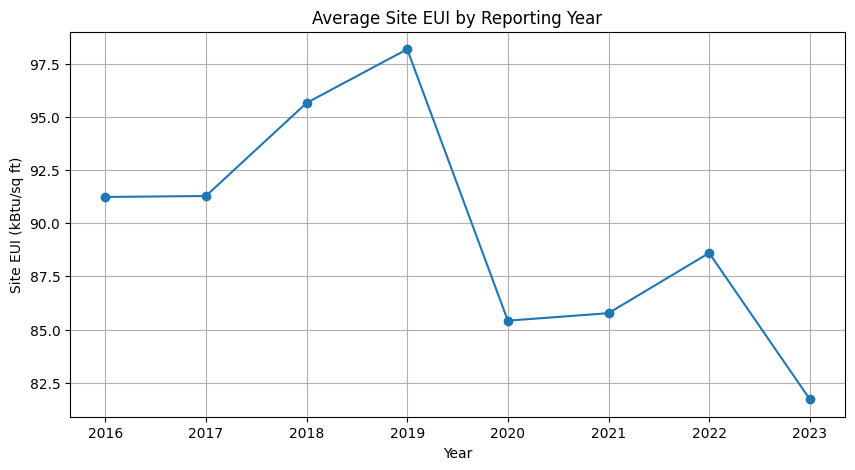

In [28]:
yearly_eui["mean"].plot(
    kind="line",
    marker="o",
    figsize=(10, 5)
)

plt.title("Average Site EUI by Reporting Year")
plt.xlabel("Year")
plt.ylabel("Site EUI (kBtu/sq ft)")
plt.grid(True)
plt.show()

In [30]:
property_eui = energy_eui.groupby(
    "Primary Property Type"
)["Site EUI (kBtu/sq ft)"].agg(
    ["count", "mean", "median"]
).sort_values("mean", ascending=True)

property_eui

,count,mean,median
Primary Property Type,,,
"Repair Services (Vehicle, Shoe, Locksmith, etc.)",6,24.266667,18.85
Lifestyle Center,7,62.000000,55.50
Pre-school/Daycare,15,70.953333,70.90
Urgent Care/Clinic/Other Outpatient,6,75.633333,65.25
Commerce de détail,1,76.300000,76.30
K-12 School,2679,77.035610,75.20
Multifamily Housing,10794,77.430749,73.90
Office,2660,77.597406,70.05
Distribution Center,1,78.200000,78.20


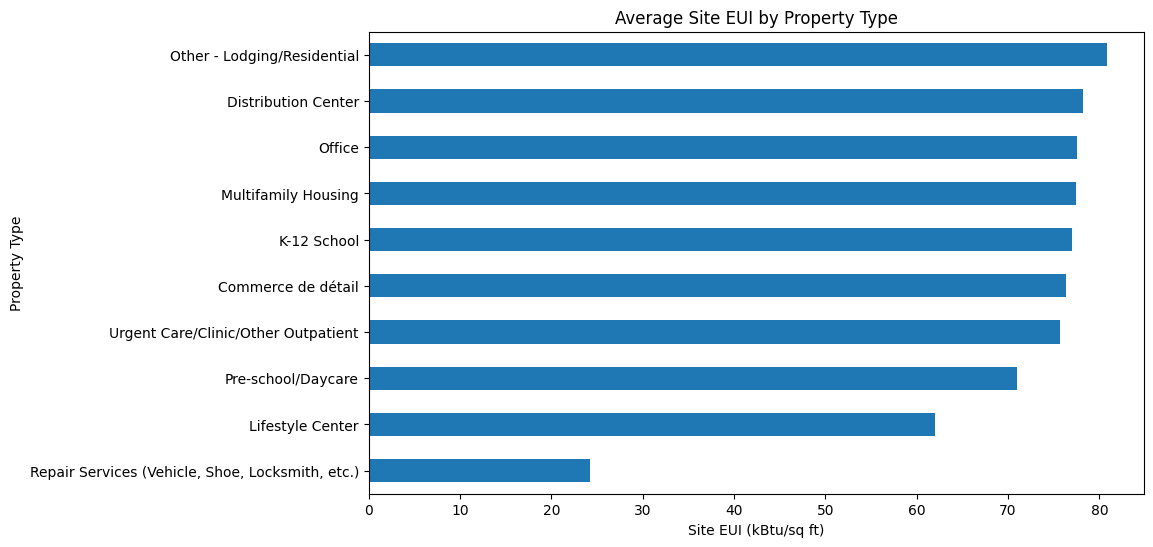

In [31]:
property_eui.head(10)["mean"].sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Average Site EUI by Property Type")
plt.xlabel("Site EUI (kBtu/sq ft)")
plt.ylabel("Property Type")
plt.show()

In [34]:
community_eui = energy_eui.groupby(
    "Community Area"
)["Site EUI (kBtu/sq ft)"].agg(
    ["count", "mean", "median"]
).sort_values("mean", ascending=False)

community_eui
# will need to clean these values! (ex. Hegewisch & hegewisch? could go to OpenRefine)

,count,mean,median
Community Area,,,
CALUMET HEIGHTS,13,168.784615,126.00
HEGEWISCH,24,156.991667,101.70
Hegewisch,3,150.100000,97.40
West Englewood,4,147.550000,77.40
PULLMAN,51,146.113725,94.10
...,...,...,...
South Chicago,6,57.866667,59.35
Edison Park,2,57.350000,57.35
Avalon Park,9,56.200000,57.60
